# Bogotá en movimiento · TransMilenio + Ray

**Computación Paralela · Maestría en Ciencias de la Información y las Comunicaciones · Universidad Distrital FJC**
Juan Felipe Rodríguez Galindo (20261595004) · Carlos Stiven Mora Hoyos (20261595003) · Docente: Nelson Enrique Vera Parra

Analítica distribuida con **Ray** sobre 14 días (11 al 24 de noviembre de 2026) del feed GTFS-Realtime de posiciones de
TransMilenio: 28.958 capturas, 3,7 GB comprimidos, 85,2 millones de reportes.

**Cómo leer este cuaderno**

- Las celdas marcadas con ☁ se corrieron **en Colab el 24 de noviembre de 2026** (CPU High-RAM, 8 vCPU, unos 70 minutos).
  No hace falta volver a correrlas: fuera de Colab solo imprimen el registro real de esa corrida
  (`resultados/log.txt` y `resultados/tiempos.jsonl`).
- Las demás corren en local en segundos o pocos minutos, sobre la muestra de `datos/raw` (739 capturas) y los resultados
  guardados en `resultados/`.
- Para ejecutarlo: `cd pipeline && uv sync && uv run --with jupyter --with matplotlib jupyter lab ../proyecto_final.ipynb`.

In [1]:
import gzip, json, sys, subprocess, tempfile, time, inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()                      # 4.ProyectoFinal
sys.path.insert(0, str(RAIZ / "pipeline"))
from tm import nucleo

EN_COLAB = "google.colab" in sys.modules
UD = {"troncal": "#ED3237", "zonal": "#1291C0", "alimentador": "#00A859", "dual": "#B49739", "gris": "#98999A", "sable": "#373435"}
plt.rcParams.update({"font.family": "serif", "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.precision", 2)
print("Colab:", EN_COLAB, "· Python", sys.version.split()[0], "· pandas", pd.__version__)

Colab: False · Python 3.12.13 · pandas 3.1.1


## 1. Los datos

Carlos archiva cada 20 s el feed `VehiclePositions` (protobuf comprimido) en
[`Fozzy3/parallel-computing-final`](https://github.com/Fozzy3/parallel-computing-final), en carpetas por **fecha UTC**.
Una captura es una foto de toda la flota en un instante.

In [2]:
raw = sorted((RAIZ / "datos/raw").rglob("*.pb.gz"))
ejemplo = RAIZ / "datos/raw/2026/11/17/positions_20261117T120044Z.pb.gz"   # 07:00:44 en Bogotá
cols = nucleo.parsear(ejemplo.read_bytes())
foto = pd.DataFrame(cols)
print(f"{len(raw)} capturas en la muestra local · {sum(p.stat().st_size for p in raw)/1e6:.0f} MB")
print(f"Captura {ejemplo.name}: {len(foto):,} buses con reporte fresco (< 5 min)".replace(",", "."))
foto.head()

739 capturas en la muestra local · 114 MB
Captura positions_20261117T120044Z.pb.gz: 5.359 buses con reporte fresco (< 5 min)


,dia,parte,captura,ts,vehicle_id,trip_id,route_id,stop_id,lat,lon
0,2026-11-17,19,1794916836,1794916798,10159,TTABA0541.1.12971,11724,61943,4.60,-74.08
1,2026-11-17,41,1794916836,1794916811,45483,TTABA1422.10.11725,14097,61957,4.62,-74.10
2,2026-11-17,23,1794916836,1794916805,10192,TTABA1331.3.12428,13278,61153,4.63,-74.08
3,2026-11-17,51,1794916836,1794916810,104535,CN2850020.3.10848,13328,55580,4.75,-74.08
4,2026-11-17,20,1794916836,1794916796,14512,TD0D50214.2.12297,13939,61984,4.61,-74.07


### Calidad de los datos

Tres problemas que el ETL tiene que resolver (detalle en `docs/evaluacion-archivador.md`):

1. **Zombis:** del 18 nov 17:30 al 19 nov ~10:00 el feed repitió los mismos 7 buses con reportes de hasta 13 días.
   Se filtran con `header.timestamp − vehicle.timestamp < 300 s`.
2. **Repetidos:** cada bus reporta cada ~52 s y se captura cada 20 s, así que el mismo `(vehicle_id, timestamp)`
   aparece varias veces. Se deduplica.
3. **Día de servicio:** las carpetas son UTC; el día de Bogotá (UTC−5) cruza dos carpetas.

In [3]:
from google.transit import gtfs_realtime_pb2

def antiguedades(ruta):
    f = gtfs_realtime_pb2.FeedMessage()
    f.ParseFromString(gzip.decompress(ruta.read_bytes()))
    return np.array([f.header.timestamp - e.vehicle.timestamp for e in f.entity if e.HasField("vehicle")])

zombi = RAIZ / "datos/raw/2026/11/19/positions_20261119T050002Z.pb.gz"   # 19 nov, 00:00 en Bogotá
for nombre, ruta in [("normal (17 nov 07:00)", ejemplo), ("congelado (19 nov 00:00)", zombi)]:
    a = antiguedades(ruta)
    print(f"{nombre:26s} reportes={len(a):5d}  frescos={np.sum(a < nucleo.FRESCO):5d}  antigüedad máx={a.max()/86400:5.1f} días")

normal (17 nov 07:00)      reportes= 5393  frescos= 5359  antigüedad máx= 74.9 días
congelado (19 nov 00:00)   reportes=    9  frescos=    0  antigüedad máx= 76.6 días


In [4]:
# Repetidos en la ventana densa del 17 (todas las capturas de 6:15 a 7:45)
ventana = [p for p in raw if "20261117T11" in p.name or "20261117T12" in p.name]
filas = pd.concat([pd.DataFrame(nucleo.parsear(p.read_bytes())) for p in ventana])
rep = 1 - len(filas.drop_duplicates(["vehicle_id", "ts"])) / len(filas)
print(f"{len(ventana)} capturas · {len(filas):,} reportes leídos · repetidos {rep:.1%}".replace(",", "."))

164 capturas · 864.958 reportes leídos · repetidos 15.2%


## 2. El pipeline

El mismo trabajo en dos modos: **secuencial** (un proceso, sin Ray: la línea base honesta) y **Ray**. La lógica está en
`pipeline/tm/nucleo.py`; `pipeline/pipeline.py` solo decide cómo se reparte.

| Etapa | Qué hace | Paralelismo en Ray |
|---|---|---|
| `etl` | `.pb.gz` → filas, filtra zombis → Parquet particionado por `dia` y `parte = crc32(vehicle_id) % 64` | **Ray Data**: `read_binary_files` + `map_batches` + `write_parquet` |
| `trayectorias` | por partición: ordenar, deduplicar, **map-matching** contra la geometría de la ruta, velocidad | **Ray Core**: una tarea `@ray.remote` por partición; geometrías en el object store con `ray.put` |
| `headways` | cruces por puntos de control cada 1 km → intervalo entre buses consecutivos | Ray Core: tareas por partición y por día |

El corazón del costo es el map-matching: proyectar cada posición sobre la polilínea de su ruta.

In [5]:
print(inspect.getsource(nucleo.proyectar))

def proyectar(p: np.ndarray, geo) -> tuple:
    """Map-matching: cada punto (n,2) a su segmento más cercano de la polilínea. Devuelve (s, desvío) en metros.
    Es O(n·m): el kernel caro del pipeline."""
    q, acum = geo
    a, b = q[:-1], q[1:]
    ab = b - a
    L2 = np.maximum((ab ** 2).sum(1), 1e-9)
    ap = p[:, None, :] - a[None, :, :]                          # (n, m, 2)
    t = np.clip((ap * ab[None]).sum(2) / L2[None], 0.0, 1.0)     # (n, m)
    proy = a[None] + t[..., None] * ab[None]
    d2 = ((p[:, None, :] - proy) ** 2).sum(2)
    j = d2.argmin(1)
    i = np.arange(len(p))
    return acum[j] + t[i, j] * np.sqrt(L2[j]), np.sqrt(d2[i, j])



In [6]:
from pipeline import correr_ray
print(inspect.getsource(correr_ray))

def correr_ray(rutas, gtfs, out: Path, cpus: int, etapas):
    os.environ.setdefault("RAY_ENABLE_UV_RUN_RUNTIME_ENV", "0")  # no empaquetar el .venv como working_dir
    import ray
    import ray.data as rd

    ray.init(num_cpus=cpus, include_dashboard=False, log_to_driver=False,
             object_store_memory=int(os.environ.get("TM_OBJ_STORE", 2 * 1024**3)))
    ctx = rd.DataContext.get_current()
    ctx.enable_progress_bars = False
    t = {}

    if "etl" in etapas:  # Ray Data: paralelismo de datos, streaming de bloques
        t0 = time.perf_counter()
        (rd.read_binary_files(rutas, override_num_blocks=max(cpus * 4, 64))
           .map_batches(nucleo.parsear_lote, batch_size=8, batch_format="numpy")
           .write_parquet(str(out / "posiciones"), partition_cols=["dia", "parte"]))
        t["etl"] = time.perf_counter() - t0

    if "trayectorias" in etapas:  # Ray Core: una tarea por partición; geometrías en el object store
        t0 = time.perf_counter()
        geos_

### Prueba local (muestra del martes 17)

Las 208 capturas locales del 17 de noviembre, secuencial contra Ray con 4 workers. Es poco volumen, así que el
arranque de Ray pesa; la medición seria es la de Colab (sección 3).

In [7]:
salida = Path(tempfile.mkdtemp())
base = [sys.executable, "pipeline.py", "--raw", "../datos/raw", "--gtfs", "../datos/gtfs/GTFS.zip",
        "--dias", "2026-11-17", "--out", str(salida / "tm")]
locales = []
for extra in (["--modo", "secuencial", "--cpus", "1"], ["--modo", "ray", "--cpus", "4"]):
    r = subprocess.run(base + extra, cwd=RAIZ / "pipeline", capture_output=True, text=True)
    reg = json.loads([l for l in r.stdout.splitlines() if l.startswith("{")][-1])
    locales.append(reg)
    print(reg["modo"], reg["cpus"], "cpus ·", reg["archivos"], "archivos ·", reg["tiempos"], "·", reg["filas"])

secuencial 1 cpus · 208 archivos · {'etl': 3.12, 'trayectorias': 42.7, 'headways': 2.11} · {'posiciones': 1011501, 'trayectorias': 874435, 'cruces': 131343, 'headways': 114873}


ray 4 cpus · 208 archivos · {'etl': 7.1, 'trayectorias': 16.22, 'headways': 0.79} · {'posiciones': 1011501, 'trayectorias': 874435, 'cruces': 131343, 'headways': 114873}


## 3. Benchmark en Colab ☁

`pipeline/colab/bench_colab.sh` en una VM de Colab (CPU High-RAM, 8 vCPU, 50 GB):

1. **Escalamiento fuerte:** el martes 17 completo (2.268 capturas, 324 MB), secuencial y Ray con 1, 2, 4 y 8 workers.
2. **Volumen:** 8 workers con 3 días hábiles y con los 14 días. La salida de 14 días alimenta `metricas.py`.

La etapa de headways se rehízo después con puntos de control (`pipeline/colab/headways_colab.sh`), porque el `stop_id`
del feed no se actualizaba antes del 18 de noviembre.

In [8]:
# ☁ Corrida del 24-nov-2026 en Colab (~60 min). Fuera de Colab solo muestra su registro.
if EN_COLAB:
    !bash pipeline/colab/bench_colab.sh
log = (RAIZ / "resultados/log.txt").read_text().splitlines()
print("\n".join(l for l in log if "hw" not in l and "HW" not in l))

2026-11-24T19:05:48Z preparando
2026-11-24T19:05:49Z datos listos: 7.7G
2026-11-24T19:15:28Z fin --dias 2026-11-17 --out /content/tmp --modo secuencial --cpus 1 --etiqueta fuerte (rc=0)
2026-11-24T19:25:46Z fin --dias 2026-11-17 --out /content/tmp --modo ray --cpus 1 --etiqueta fuerte (rc=0)
2026-11-24T19:31:51Z fin --dias 2026-11-17 --out /content/tmp --modo ray --cpus 2 --etiqueta fuerte (rc=0)
2026-11-24T19:34:55Z fin --dias 2026-11-17 --out /content/tmp --modo ray --cpus 4 --etiqueta fuerte (rc=0)
2026-11-24T19:37:13Z fin --dias 2026-11-17 --out /content/tmp --modo ray --cpus 8 --etiqueta fuerte (rc=0)
2026-11-24T19:43:15Z fin --dias 2026-11-12,2026-11-13,2026-11-17 --out /content/tmp --modo ray --cpus 8 --etiqueta volumen (rc=0)
2026-11-24T20:04:55Z fin --dias 2026-11-11,2026-11-12,2026-11-13,2026-11-14,2026-11-15,2026-11-16,2026-11-17,2026-11-18,2026-11-19,2026-11-20,2026-11-21,2026-11-22,2026-11-23,2026-11-24 --out /content/completo --modo ray --cpus 8 --etiqueta volumen (rc=0)


In [9]:
# ☁ Rehacer headways con puntos de control (~3 min). Fuera de Colab solo muestra su registro.
if EN_COLAB:
    !bash pipeline/colab/headways_colab.sh
print("\n".join(l for l in log if "hw" in l or "HW" in l))

2026-11-24T20:12:37Z fin hw --dias 2026-11-17 --out /content/d17 --modo secuencial --cpus 1 --etiqueta fuerte-hw (rc=0)
2026-11-24T20:12:54Z fin hw --dias 2026-11-17 --out /content/d17 --modo ray --cpus 1 --etiqueta fuerte-hw (rc=0)
2026-11-24T20:13:09Z fin hw --dias 2026-11-17 --out /content/d17 --modo ray --cpus 2 --etiqueta fuerte-hw (rc=0)
2026-11-24T20:13:22Z fin hw --dias 2026-11-17 --out /content/d17 --modo ray --cpus 4 --etiqueta fuerte-hw (rc=0)
2026-11-24T20:13:36Z fin hw --dias 2026-11-17 --out /content/d17 --modo ray --cpus 8 --etiqueta fuerte-hw (rc=0)
2026-11-24T20:14:11Z fin hw --dias 2026-11-11 --out /content/completo --modo ray --cpus 8 --etiqueta volumen-hw (rc=0)
2026-11-24T20:14:32Z TERMINADO-HW


In [10]:
t = pd.read_json(RAIZ / "resultados/tiempos.jsonl", lines=True)
t["workers"] = np.where(t.modo == "secuencial", 0, t.cpus)
fuerte = t[t.etiqueta == "fuerte"].set_index("workers")
hw = t[t.etiqueta == "fuerte-hw"].set_index("workers")
tab = pd.DataFrame({
    "etl (s)": fuerte.tiempos.str["etl"],
    "trayectorias (s)": fuerte.tiempos.str["trayectorias"],
    "headways (s)": hw.tiempos.str["headways"],       # versión final (puntos de control)
})
tab["total (s)"] = tab.sum(axis=1)
tab["speedup"] = tab.loc[0, "total (s)"] / tab["total (s)"]
tab["eficiencia"] = tab.speedup / tab.index.where(tab.index > 0, 1)
tab.index = ["secuencial" if w == 0 else f"ray · {w}" for w in tab.index]
tab

,etl (s),trayectorias (s),headways (s),total (s),speedup,eficiencia
secuencial,32.74,540.13,6.25,579.12,1.00,1.00
ray · 1,49.35,553.87,7.01,610.23,0.95,0.95
ray · 2,39.84,309.80,4.46,354.10,1.64,0.82
ray · 4,19.89,147.74,3.10,170.73,3.39,0.85
ray · 8,17.35,104.28,2.88,124.51,4.65,0.58


speedup con 8 workers = 4.65×  →  p ≈ 0.90  (techo teórico 1/(1-p) ≈ 9.7×)


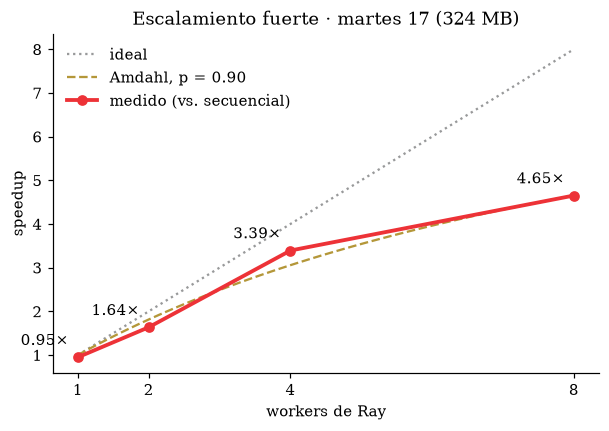

In [11]:
# Fracción paralela de Amdahl estimada con el punto de 8 workers: S = 1 / ((1-p) + p/n)
S8, n = tab.loc["ray · 8", "speedup"], 8
p = (1 - 1 / S8) / (1 - 1 / n)
print(f"speedup con 8 workers = {S8:.2f}×  →  p ≈ {p:.2f}  (techo teórico 1/(1-p) ≈ {1/(1-p):.1f}×)")

w = np.array([1, 2, 4, 8])
med = tab.loc[[f"ray · {k}" for k in w], "speedup"].values
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(w, w, ls=":", c=UD["gris"], label="ideal")
xs = np.linspace(1, 8, 50)
ax.plot(xs, 1 / ((1 - p) + p / xs), ls="--", c=UD["dual"], label=f"Amdahl, p = {p:.2f}")
ax.plot(w, med, "o-", c=UD["troncal"], lw=2.5, label="medido (vs. secuencial)")
for x, y in zip(w, med):
    ax.annotate(f"{y:.2f}×", (x, y), textcoords="offset points", xytext=(-6, 8), ha="right")
ax.set(xlabel="workers de Ray", ylabel="speedup", xticks=w, title="Escalamiento fuerte · martes 17 (324 MB)")
ax.legend(frameon=False); plt.show()

In [12]:
# Por etapa: dónde está el paralelismo y dónde no
etapas = tab[["etl (s)", "trayectorias (s)", "headways (s)"]]
(etapas.loc["secuencial"] / etapas.loc["ray · 8"]).rename("speedup con 8 workers").to_frame()

,speedup con 8 workers
etl (s),1.89
trayectorias (s),5.18
headways (s),2.17


In [13]:
# Volumen con 8 workers: 1, 3 y 14 días
vol = t[(t.cpus == 8) & t.etiqueta.isin(["fuerte", "volumen"])].copy()
vol["días"] = vol.dias.str.count(",") + 1
vol["total (s)"] = vol.tiempos.apply(lambda d: d["etl"] + d["trayectorias"] + d["headways"])
vol["MB/s"] = vol.mb / vol["total (s)"]
vol["reportes (M)"] = vol.filas.str["posiciones"] / 1e6
vol[["días", "archivos", "mb", "reportes (M)", "total (s)", "MB/s"]].reset_index(drop=True)

,días,archivos,mb,reportes (M),total (s),MB/s
0,1,2268,323.6,7.52,125.96,2.57
1,3,6797,992.5,22.82,342.32,2.90
2,14,28958,3708.5,85.21,1280.15,2.90


## 4. Resultados sobre la ciudad

`pipeline/metricas.py` reduce la salida de los 14 días a `resultados/metricas.json`:

- **Velocidad comercial** = Σdistancia / Σtiempo (no la mediana de velocidades instantáneas: un bus parado aporta ceros).
- **Headway** entre buses consecutivos de la misma ruta en cada punto de control.
- **Bunching** = intervalo menor al 25 % de la mediana de esa ruta y ese punto.

In [14]:
m = json.loads((RAIZ / "resultados/metricas.json").read_text())
tot = m["totales"]
print(f"reportes limpios {tot['reportes']/1e6:.1f} M · emparejados con su ruta {tot['emparejado_pct']} %")
print(f"velocidad comercial en el pico (días hábiles) {m['velocidad_pico_habil']} km/h")
print(f"headway mediano {m['headway_mediana_min']} min · bunching {m['bunching_pct']} % de los intervalos")
vd = pd.DataFrame(m["velocidad_dia"]).set_index("dia")
vd.index = pd.to_datetime(vd.index).strftime("%a %d")
vd

reportes limpios 60.8 M · emparejados con su ruta 98.4 %
velocidad comercial en el pico (días hábiles) 15.2 km/h
headway mediano 10.7 min · bunching 12.5 % de los intervalos


,v_comercial,alimentador,dual,troncal,zonal
dia,,,,,
Wed 11,13.27,10.71,15.22,19.03,12.49
Thu 12,13.48,11.87,15.30,20.19,12.58
Fri 13,13.23,11.44,15.61,20.33,12.25
Sat 14,14.52,11.61,18.70,22.00,13.39
Sun 15,17.10,13.27,20.51,21.78,16.62
Mon 16,17.81,13.37,20.77,22.09,17.46
Tue 17,13.53,11.83,14.89,19.72,12.52
Wed 18,13.79,13.19,15.90,21.20,12.40
Thu 19,14.51,13.29,17.28,19.77,13.44


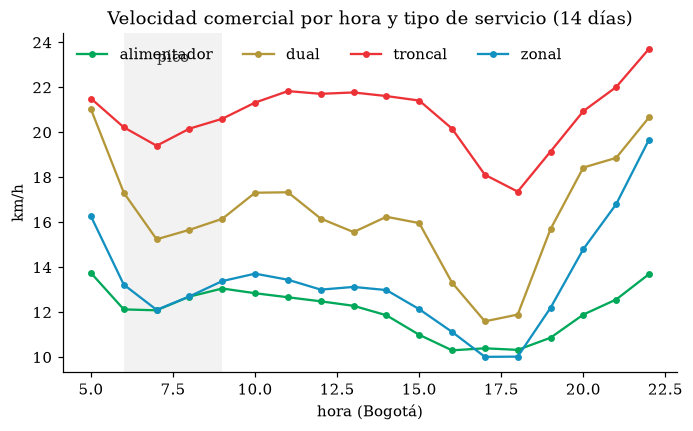

In [15]:
fig, ax = plt.subplots(figsize=(7.2, 4))
for tipo, serie in m["velocidad_hora_tipo"].items():
    s = pd.Series(serie).rename(index=int).sort_index()
    s = s[(s.index >= 5) & (s.index <= 22)]
    ax.plot(s.index, s.values, "o-", ms=3.5, c=UD[tipo], label=tipo)
ax.axvspan(6, 8.99, color=UD["gris"], alpha=0.12, lw=0)
ax.text(7.5, ax.get_ylim()[1] * 0.97, "pico", ha="center", va="top", color=UD["sable"])
ax.set(xlabel="hora (Bogotá)", ylabel="km/h", title="Velocidad comercial por hora y tipo de servicio (14 días)")
ax.legend(frameon=False, ncol=4); plt.show()

In [16]:
pd.DataFrame({"bunching (%)": m["bunching_tipo"]}).sort_values("bunching (%)", ascending=False)

,bunching (%)
dual,16.2
zonal,13.1
troncal,10.9
alimentador,7.6


In [17]:
# Tramos de 500 m más lentos de las troncales en el pico (al menos 300 observaciones)
pd.DataFrame(m["tramos_lentos"]).rename(columns={"km": "km desde el inicio", "v": "km/h", "n": "observaciones"})

,ruta,km desde el inicio,km/h,observaciones
0,H15 · Portal Tunal,19.5,4.2,345
1,1 · Universidades,0.5,4.4,342
2,H20 · Portal Usme,15.5,4.9,325
3,A60 · Calle 72,13.0,6.0,360
4,D22 · Portal 80,6.0,7.1,304
5,E42 · 7 de Agosto,10.0,7.5,560
6,K43 · P. ElDorado,16.0,7.7,469
7,K43 · P. ElDorado,10.0,8.1,482
8,E48 · CAD,10.0,8.2,410
9,B72 · Toberín,10.5,8.2,312


## 5. Conclusiones

- **Speedup 4,65× con 8 workers** frente al mismo código en un solo proceso; la fracción paralela estimada es
  p ≈ 0,90. El map-matching escala casi lineal (5,2×); el ETL se frena por la lectura de miles de archivos
  pequeños (1,9×) y los headways son casi todo arranque y reducción (2,2×).
- **Ray con 1 worker es más lento que el secuencial** (610 s contra 579 s): es el costo de Ray Data, el object store
  y el planificador. Por eso la línea base es el secuencial y no Ray con 1.
- **Los 14 días (3,7 GB, 85 M de reportes) tardan 21 minutos** en una sola VM de 8 vCPU.
- La flota anda a **15,2 km/h en el pico** de los días hábiles (unos 17 km/h en domingo y festivo), el headway
  mediano es **10,7 min** y **1 de cada 8 intervalos** es bunching.
- **Límites:** solo 14 días; `trip_id` cambia cada día y el GTFS estático solo se guarda desde el 24, así que no se
  compara contra el horario programado; las geometrías son las del GTFS del 24.